# FinRL Assignment 1 - Patrick Xiong (sx2434)
Latest WRDS common-source results. These cells inspect frozen result snapshots; source-to-model replay is in README. No licensed raw data is included.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image
P=Path.cwd()
facts=json.loads((P/'evidence/final_research_facts.json').read_text())
comparison=pd.read_csv(P/'results/three_strategy_comparison.csv').set_index('label')
display(comparison[['cumulative','cagr','volatility','sharpe_rf0','max_drawdown','annual_turnover']].round(6))

,cumulative,cagr,volatility,sharpe_rf0,max_drawdown,annual_turnover
label,,,,,,
QQQ enhancement,2.044466,0.228240,0.223898,1.032882,-0.330490,1.640929
"Pure stocks, validation choice",1.920442,0.218844,0.292630,0.823483,-0.311993,6.760229
SPY enhancement,1.593904,0.192447,0.188530,1.030576,-0.243021,1.573209
"Pure stocks, RF only",2.142858,0.235475,0.293812,0.867643,-0.325863,6.701729
"QQQ enhancement, RF only",2.091046,0.231689,0.223660,1.046323,-0.331696,1.632932
SPY,1.549081,0.188615,0.175071,1.077386,-0.244974,0.000000
QQQ,1.918565,0.218699,0.229933,0.977663,-0.351225,0.000000


In [2]:
c=comparison.cumulative
assert c['QQQ enhancement'] > c['Pure stocks, validation choice'] > c['SPY enhancement'] > c['SPY']
assert c['Pure stocks, RF only'] > c['QQQ enhancement'] > c['QQQ']
print('Validation-selected headline ranking and separate RF-only comparator verified.')

Validation-selected headline ranking and separate RF-only comparator verified.


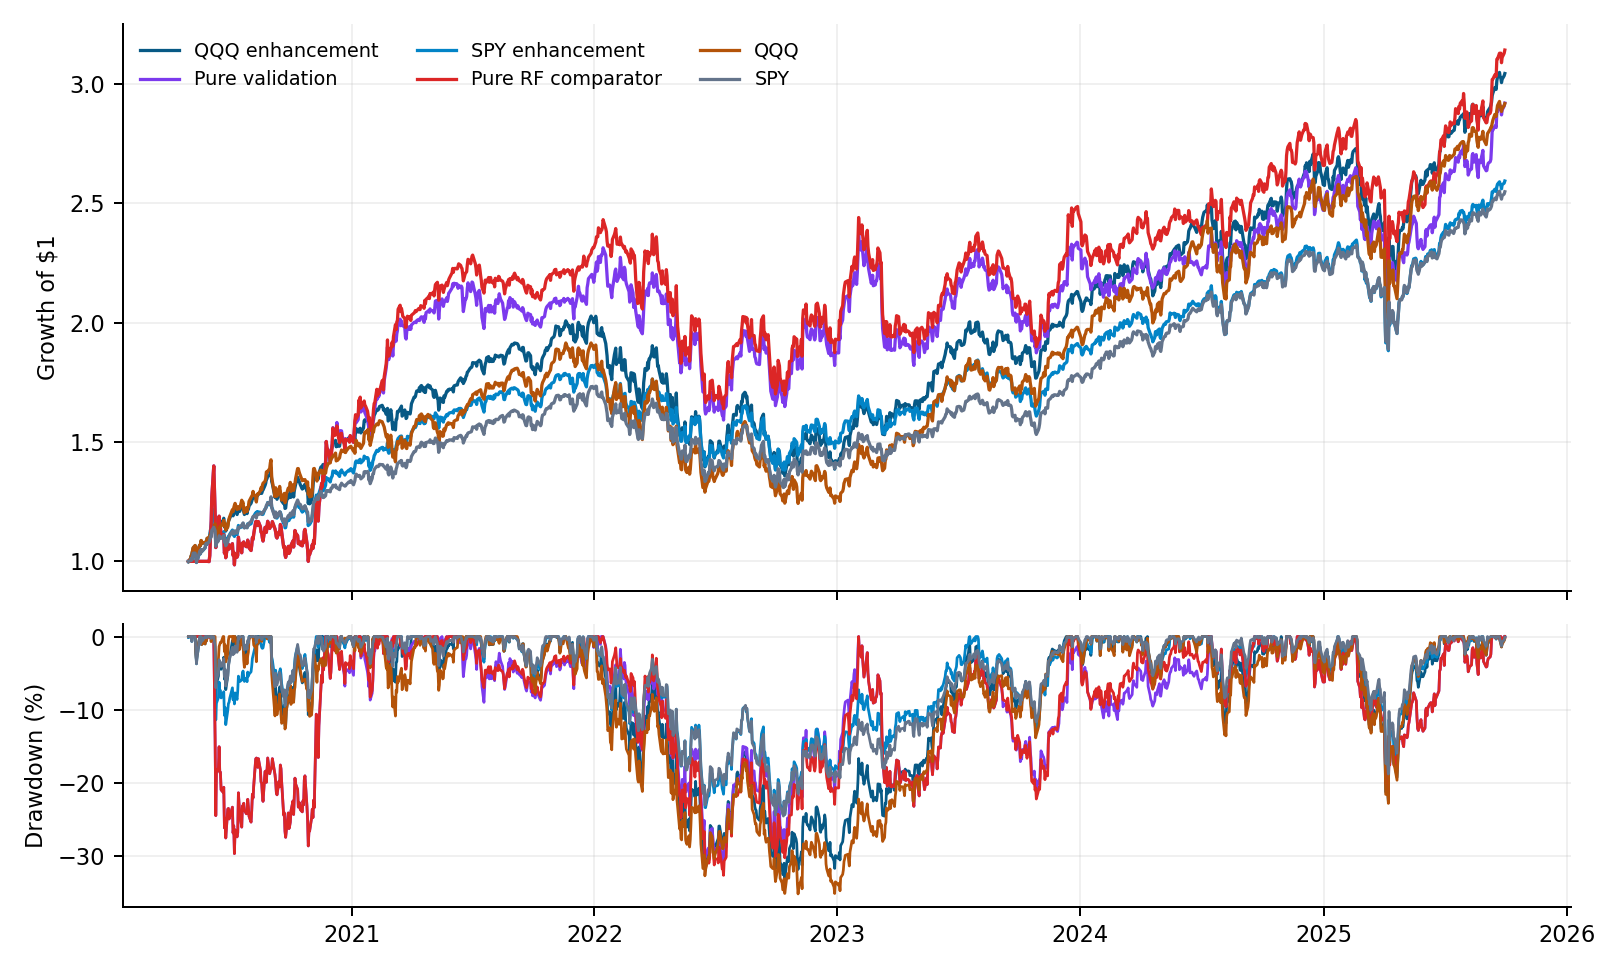

In [3]:
nav=pd.read_csv(P/'results/three_strategy_nav.csv',index_col=0,parse_dates=True)
assert len(nav)==1361 and str(nav.index[0].date())=='2020-05-01' and str(nav.index[-1].date())=='2025-09-30'
for label,row in comparison.iterrows():
    assert abs(nav[row.strategy].iloc[-1]-1-row.cumulative)<1e-12
display(Image(filename=str(P/'results/three_strategy_paths.png')))

In [4]:
stress=pd.read_csv(P/'results/stress_comparison.csv').set_index('label')
assert stress.loc['QQQ enhancement','cumulative'] > c['QQQ']
assert stress.loc['Pure stocks, RF only','cumulative'] > c['QQQ']
assert stress.loc['Pure stocks, validation choice','cumulative'] < c['QQQ']
display(stress.round(6))

,cumulative,cagr,volatility,sharpe_rf0,max_drawdown,annual_turnover
label,,,,,,
QQQ enhancement,1.985702,0.223828,0.223852,1.016913,-0.330931,1.635347
"Pure stocks, validation choice",1.661806,0.198151,0.292146,0.765539,-0.312046,6.752095
SPY enhancement,1.572144,0.190594,0.188371,1.023001,-0.243050,1.572751
"Pure stocks, RF only",2.010295,0.225683,0.293933,0.840220,-0.312020,6.695380
"QQQ enhancement, RF only",2.062562,0.229585,0.223695,1.038520,-0.329333,1.628650


In [5]:
seeds=pd.read_csv(P/'results/QQQ_seed_robustness.csv')
assert len(seeds)==11 and seeds.beats_QQQ.all()
assert facts['QQQ_model_wins']=={'rf':15,'xgb':6,'gbm':1}
display(pd.read_csv(P/'results/QQQ_selected_feature_importance.csv'))
print('Seed sensitivity range:', seeds.cumulative.min(), seeds.cumulative.max())

,feature,normalized_tree_importance
0,momentum_21,0.242114
1,momentum_252,0.228302
2,volatility_63,0.199151
3,momentum_63,0.113501
4,momentum_126,0.113216
5,drawdown_126,0.103715


Seed sensitivity range: 1.97468193979374 2.090832029860376


In [6]:
for name,folder in [('SPY',P/'evidence'),('QQQ',P/'experiments/qqq/evidence'),('Absolute',P/'experiments/absolute/evidence')]:
    proof=json.loads((folder/'bias_proof/bias_proof_summary.json').read_text())
    assert proof['official_member_quarter_cases']==20675 and proof['forecast_cases']==11083
    assert proof['missing_official_members']==0 and proof['source_label_clock_breaches']==0
    assert proof['executed_fit_score_predict_records_verified']==858
    assert proof['eligible_failed_bank_missing_label_causes_error']
    assert proof['poisoned_future_metadata_and_inference_targets_maximum_prediction_difference']<1e-12
    print(name, 'recorded membership/clock/poisoning controls passed; scope:', proof['scope'])

SPY recorded membership/clock/poisoning controls passed; scope: Finite proof of frozen-source historical-universe retention and decision/training causality; conditional on CRSP historical record semantics.
QQQ recorded membership/clock/poisoning controls passed; scope: Finite proof of frozen-source historical-universe retention and decision/training causality; conditional on CRSP historical record semantics.
Absolute recorded membership/clock/poisoning controls passed; scope: Finite proof of frozen-source historical-universe retention and decision/training causality; conditional on CRSP historical record semantics.


In [7]:
receipt=facts['QQQ_independent']
assert receipt['independent_QQQ_relative_label_cases']==20169
assert receipt['maximum_QQQ_relative_target_difference']<1e-12
assert receipt['strategies']==21 and receipt['days']==1361
assert receipt['maximum_daily_nav_difference']<1e-10
print(receipt)
print('These snapshot checks do not establish untouched-holdout alpha or original vendor-vintage completeness.')

{'independent_raw_CRSP_return_reconstruction': True, 'independent_dollar_ledger': True, 'production_backtest_functions_imported': False, 'independent_selection_from_raw_prior_quotes': True, 'maximum_prepared_return_difference': 0.0, 'independent_observed_label_cases': 20169, 'maximum_observed_label_difference': 0.0, 'independent_QQQ_relative_label_cases': 20169, 'maximum_QQQ_relative_target_difference': 1.7763568394002505e-15, 'strategies': 21, 'days': 1361, 'maximum_daily_nav_difference': 3.241851231905457e-14}
These snapshot checks do not establish untouched-holdout alpha or original vendor-vintage completeness.
